# PathSnap — Dataset Validation & Exploratory Data Analysis (EDA)

This notebook implements **Dataset Exploration.pdf** and **Deliverables.pdf (Section 2.2: Dataset Understanding and Exploratory Data Analysis)** directly against the read-only `Student folder.zip` archive.

### Dataset Partition & Data-Leakage Policy
| Partition | Trips | ID Range / Status | Permitted Use |
|---|---:|---|---|
| `train` | 80 | Subset of `00000001`–`00000099` | EDA, preprocessing design, feature engineering, CV & training |
| `student_test` | 10 | `00000000, 00000007, 00000009, 00000040, 00000052, 00000056, 00000065, 00000076, 00000077, 00000091` | Development-stage evaluation only (always reported separately from `train`) |
| `evaluator_test` | 10 | `00000015, 00000017, 00000023, 00000030, 00000049, 00000059, 00000067, 00000073, 00000087, 00000094` | **Not present** in `Student folder.zip`; reserved strictly for final evaluation |

**Strict rules enforced here:**
1. `Student folder.zip` is read strictly in read-only mode and never modified.
2. `train` and `student_test` are summarised and plotted separately in every audit table and figure.
3. All ground-truth `.route` noise statistics and candidate-radius sweeps are computed **strictly on `train` (80 trips)** so no test labels influence candidate radius or feature thresholds.

## 1. Raw File Schema, Coordinate Order & Environment Setup

The four per-trip files have **no headers** and must be parsed with exact column ordering:

| Extension | Columns | Meaning |
|---|---|---|
| `.track` | `longitude, latitude, timestamp_s` | Chronological GPS observations |
| `.nodes` | `longitude, latitude` | Road-network vertices (0-based row index = `node_id`) |
| `.arcs` | `from_node_id, to_node_id` | Directed road segments (0-based row index = `arc_id`) |
| `.route` | `arc_id` | Chronological reference road-arc sequence (**run-length compressed**, not 1 row per GPS point) |

> **Coordinate order warning:** `.track` and `.nodes` store `(longitude, latitude)`, whereas Folium / Leaflet require `[latitude, longitude]`.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from collections import Counter, defaultdict
import io
import math
import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle
import folium

plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 180,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'font.size': 10,
})

# Locate Student folder.zip safely without modifying it
candidates = [
    Path('Student folder.zip'),
    Path('../Student folder.zip'),
    Path('ml_hackathon/Student folder.zip'),
    Path('/mnt/data/Student folder.zip'),
]
if Path('/kaggle/input').exists():
    candidates += list(Path('/kaggle/input').glob('**/Student folder.zip'))

DATA_ZIP = next((p for p in candidates if p.is_file()), None)
if DATA_ZIP is None:
    raise FileNotFoundError('Place Student folder.zip beside this notebook or in the repository root, or set DATA_ZIP explicitly.')

OUT = Path('PathSnap_EDA_outputs')
OUT.mkdir(exist_ok=True)
print(f'Reading dataset archive: {DATA_ZIP} ({DATA_ZIP.stat().st_size:,} bytes)')
print(f'Writing outputs to:      {OUT}')

Reading dataset archive: Student folder.zip (29,410,509 bytes)
Writing outputs to:      PathSnap_EDA_outputs


In [2]:
EARTH_RADIUS_M = 6371000.0
TRAIN_COLOR = '#2563eb'
TEST_COLOR = '#ea580c'
ROUTE_COLOR = '#16a34a'


def load_file(zf: ZipFile, split: str, trip_id: str, ext: str, dtype=float) -> np.ndarray:
    """Load a headerless whitespace-delimited trip file safely with consistent rank."""
    name = f'Student folder/{split}/{trip_id}/{trip_id}.{ext}'
    raw = zf.read(name)
    if not raw.strip():
        ncols = 3 if ext == 'track' else (2 if ext in ('nodes', 'arcs') else 1)
        return np.empty((0, ncols), dtype=dtype) if ext != 'route' else np.empty((0,), dtype=dtype)
    ndmin = 2 if ext in ('track', 'nodes', 'arcs') else 1
    arr = np.loadtxt(io.BytesIO(raw), dtype=dtype, ndmin=ndmin)
    return arr.ravel() if ext == 'route' else arr


def haversine_m(lat1, lon1, lat2, lon2):
    """Great-circle Haversine distance in meters."""
    lat1_r = np.radians(lat1)
    lat2_r = np.radians(lat2)
    dlat = lat2_r - lat1_r
    dlon = np.radians(lon2 - lon1)
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1_r) * np.cos(lat2_r) * np.sin(dlon / 2.0) ** 2
    return 2.0 * EARTH_RADIUS_M * np.arctan2(np.sqrt(a), np.sqrt(np.maximum(0.0, 1.0 - a)))


def to_local_xy(lon, lat, lon0: float, lat0: float):
    """Project WGS84 (lon, lat) onto a local tangent plane in meters centered at (lon0, lat0)."""
    cos0 = math.cos(math.radians(lat0))
    x = EARTH_RADIUS_M * np.radians(lon - lon0) * cos0
    y = EARTH_RADIUS_M * np.radians(lat - lat0)
    return x, y


def point_to_segments_min_dist_m(pts_xy: np.ndarray, seg_a: np.ndarray, seg_b: np.ndarray, chunk_pts: int = 256) -> np.ndarray:
    """Exact vectorized Euclidean perpendicular distance from pts_xy (N,2) to line segments [seg_a, seg_b] (S,2)."""
    if len(pts_xy) == 0:
        return np.empty(0, dtype=np.float64)
    if len(seg_a) == 0:
        return np.full(len(pts_xy), np.inf, dtype=np.float64)
    ab = seg_b - seg_a  # (S, 2)
    ab_len2 = np.sum(ab * ab, axis=1)  # (S,)
    safe_len2 = np.where(ab_len2 > 0.0, ab_len2, 1.0)
    out = np.empty(len(pts_xy), dtype=np.float64)
    for start in range(0, len(pts_xy), chunk_pts):
        p = pts_xy[start:start + chunk_pts]  # (B, 2)
        ap_x = p[:, 0:1] - seg_a[None, :, 0]
        ap_y = p[:, 1:2] - seg_a[None, :, 1]
        t = (ap_x * ab[None, :, 0] + ap_y * ab[None, :, 1]) / safe_len2[None, :]
        t = np.where(ab_len2[None, :] > 0.0, np.clip(t, 0.0, 1.0), 0.0)
        dx = ap_x - t * ab[None, :, 0]
        dy = ap_y - t * ab[None, :, 1]
        out[start:start + chunk_pts] = np.sqrt(np.min(dx * dx + dy * dy, axis=1))
    return out

In [3]:
with ZipFile(DATA_ZIP) as zf:
    entries = zf.namelist()
    non_std = [n for n in entries if not n.endswith('/') and not any(n.endswith(e) for e in ('.track', '.nodes', '.arcs', '.route'))]
    trip_ids = {
        split: sorted({
            p.split('/')[2]
            for p in entries
            if p.startswith(f'Student folder/{split}/') and p.endswith('.track')
        })
        for split in ('train', 'student_test')
    }
    overlap = sorted(set(trip_ids['train']) & set(trip_ids['student_test']))
    unseen_ids = sorted(set(f'{i:08d}' for i in range(100)) - set(trip_ids['train']) - set(trip_ids['student_test']))

    print('Archive validation:')
    print(f'  Total zip entries:          {len(entries)}')
    print(f'  Non-standard files:         {non_std}')
    print(f'  Partition trip counts:      { {k: len(v) for k, v in trip_ids.items()} }')
    print(f'  Train/student_test overlap: {overlap}')
    print(f'  Missing IDs (evaluator):    {unseen_ids}')

    sample_id = '00000001'
    s_track = load_file(zf, 'train', sample_id, 'track')
    s_nodes = load_file(zf, 'train', sample_id, 'nodes')
    s_arcs = load_file(zf, 'train', sample_id, 'arcs', np.int64)
    s_route = load_file(zf, 'train', sample_id, 'route', np.int64)

print('\nSample train trip 00000001:')
for name, arr in [('track', s_track), ('nodes', s_nodes), ('arcs', s_arcs), ('route', s_route)]:
    print(f'  {name:6s}: shape={str(arr.shape):12s}, dtype={str(arr.dtype):8s}, sample={arr[:3].tolist()}')

Archive validation:
  Total zip entries:          453
  Non-standard files:         []
  Partition trip counts:      {'train': 80, 'student_test': 10}
  Train/student_test overlap: []
  Missing IDs (evaluator):    ['00000015', '00000017', '00000023', '00000030', '00000049', '00000059', '00000067', '00000073', '00000087', '00000094']

Sample train trip 00000001:
  track : shape=(1315, 3)   , dtype=float64 , sample=[[8.595203, 49.844053, 1.0], [8.595294, 49.844441, 2.0], [8.595352, 49.844883, 3.0]]
  nodes : shape=(88809, 2)  , dtype=float64 , sample=[[8.581679, 49.85788], [8.584637, 49.858295], [8.580173, 49.858567]]
  arcs  : shape=(165790, 2) , dtype=int64   , sample=[[0, 281], [0, 1], [0, 5]]
  route : shape=(525,)      , dtype=int64   , sample=[2641, 64973, 133948]


## 2. Full 90-Trip Quality, Timestamp, Road-Graph & Reference-Route Audit

We audit all 90 trips (`80 train`, `10 student_test`) with fixes for subtle data traps uncovered during validation:
1. **Float-safe timestamp diffs (`dt = np.round(np.diff(t), 6)`)**: Trips `train/00000002`, `train/00000071`, and `train/00000097` contain fractional timestamps (`7.2`, `2.003`, `1.015s` drift) where unrounded `np.diff(t) == 1` misses exact `1.0s` steps due to IEEE-754 rounding (`0.9999999999999982`).
2. **Gap-regime separation (`>10s` and `>60s`)**: Separating **parked/ignition-off pauses** (`dist < 50 m`) from **moving signal dropouts** (`dist >= 50 m`).
3. **1-second GPS jitter inflation**: Comparing raw 1s cumulative step distance against 10s-subsampled displacement and `.route` network length.
4. **Directed road-network edge cases**: Indexing parallel `(u, v)` edges strictly by `arc_id` (not `(u, v)` pairs), detecting self-loops (`u == v`) and distinct-node zero-length arcs (`nodes[u] == nodes[v]`), and computing both **weak** and **strong** connected components plus sink/source dead-ends.
5. **Reference `.route` checks**: Detecting broken directed chains (`arcs[r_k, 1] != arcs[r_{k+1}, 0]`), immediate `u->v->u` U-turn spurs, parallel-arc traversals, and route-to-GPS length ratios.

In [4]:
rows = []
file_rows = []
gap_rows = []
route_break_rows = []

with ZipFile(DATA_ZIP) as zf:
    for split, ids in trip_ids.items():
        for trip_id in ids:
            gps = load_file(zf, split, trip_id, 'track')
            nodes = load_file(zf, split, trip_id, 'nodes')
            arcs = load_file(zf, split, trip_id, 'arcs', np.int64)
            route = load_file(zf, split, trip_id, 'route', np.int64)

            lon, lat, t = gps[:, 0], gps[:, 1], gps[:, 2]
            valid = np.isfinite(gps).all(axis=1) & (np.abs(lon) <= 180.0) & (np.abs(lat) <= 90.0)
            consec_dup_coords = int(np.sum((lon[1:] == lon[:-1]) & (lat[1:] == lat[:-1]))) if len(gps) > 1 else 0
            non_int_t = bool(np.any(np.abs(t - np.round(t)) > 1e-9))

            # Float-safe timestamp differences
            dt_raw = np.diff(t)
            dt = np.round(dt_raw, 6)
            usable_pair = valid[1:] & valid[:-1] & np.isfinite(dt) & (dt > 0.0)

            step_dist = np.full(len(dt), np.nan)
            step_dist[usable_pair] = haversine_m(
                lat[:-1][usable_pair], lon[:-1][usable_pair],
                lat[1:][usable_pair], lon[1:][usable_pair],
            )
            speed_kmh = step_dist[usable_pair] / dt[usable_pair] * 3.6
            near_stationary = int(np.sum(step_dist[usable_pair] < 0.5))

            # 10-step smoothed trajectory distance to measure 1s GPS jitter inflation
            idx10 = np.arange(0, len(gps), 10)
            if idx10[-1] != len(gps) - 1:
                idx10 = np.append(idx10, len(gps) - 1)
            dist_10s_km = float(np.sum(haversine_m(lat[idx10[:-1]], lon[idx10[:-1]], lat[idx10[1:]], lon[idx10[1:]])) / 1000.0) if len(idx10) > 1 else 0.0

            # Classify gaps > 10s and > 60s by spatial displacement
            gt60_mask = usable_pair & (dt > 60.0)
            gt60_stationary = int(np.sum(gt60_mask & (step_dist < 50.0)))
            gt60_moving = int(np.sum(gt60_mask & (step_dist >= 50.0)))

            for idx in np.where(usable_pair & (dt > 10.0))[0]:
                d_m = float(step_dist[idx])
                d_t = float(dt[idx])
                gap_rows.append({
                    'partition': split,
                    'trip_id': trip_id,
                    'step_idx': int(idx),
                    'dt_s': d_t,
                    'dist_m': d_m,
                    'eff_speed_kmh': d_m / d_t * 3.6,
                    'regime': 'stationary_pause (<50m)' if d_m < 50.0 else 'moving_dropout (>=50m)',
                })

            # Local coordinate projection diagnostics
            med_lon = float(np.median(lon[valid]))
            med_lat = float(np.median(lat[valid]))
            cos_lat = math.cos(math.radians(med_lat))

            # Directed road graph diagnostics
            n_nodes = len(nodes)
            n_arcs = len(arcs)
            endpoint_valid = (arcs >= 0).all(axis=1) & (arcs < n_nodes).all(axis=1)
            va = arcs[endpoint_valid]
            out_deg = np.bincount(va[:, 0], minlength=n_nodes)
            in_deg = np.bincount(va[:, 1], minlength=n_nodes)
            tot_deg = out_deg + in_deg

            self_loops = int(np.sum(va[:, 0] == va[:, 1]))
            node_eq = np.all(nodes[va[:, 0]] == nodes[va[:, 1]], axis=1)
            zero_len_distinct = int(np.sum(node_eq & (va[:, 0] != va[:, 1])))
            dup_nodes = int(n_nodes - len(np.unique(nodes, axis=0))) if n_nodes else 0

            # Parallel (u, v) edge detection via packed 64-bit key
            arc_keys = va[:, 0].astype(np.int64) * (n_nodes + 1) + va[:, 1].astype(np.int64)
            uniq_keys, key_counts = np.unique(arc_keys, return_counts=True)
            dup_parallel_arcs = int(len(va) - len(uniq_keys))
            rev_keys = va[:, 1].astype(np.int64) * (n_nodes + 1) + va[:, 0].astype(np.int64)
            bidir_frac = float(np.mean(np.isin(uniq_keys, rev_keys))) if len(uniq_keys) else np.nan

            graph = coo_matrix(
                (np.ones(len(va), dtype=np.int8), (va[:, 0], va[:, 1])),
                shape=(n_nodes, n_nodes),
            ).tocsr()
            n_weak, weak_labels = connected_components(graph, directed=False)
            n_strong, strong_labels = connected_components(graph, directed=True, connection='strong')
            largest_weak = float(np.bincount(weak_labels).max() / n_nodes) if n_nodes else np.nan
            largest_strong = float(np.bincount(strong_labels).max() / n_nodes) if n_nodes else np.nan

            # Reference route diagnostics
            valid_route = (route >= 0) & (route < n_arcs)
            rr = route[valid_route]
            consec_dup_route = int(np.sum(rr[:-1] == rr[1:])) if len(rr) > 1 else 0
            r_arcs = arcs[rr]
            directed_ok = (r_arcs[:-1, 1] == r_arcs[1:, 0]) if len(rr) > 1 else np.array([], dtype=bool)
            route_breaks = int(np.sum(~directed_ok)) if len(directed_ok) else 0
            direct_chain_frac = float(np.mean(directed_ok)) if len(directed_ok) else np.nan
            share_node_frac = float(np.mean(
                (r_arcs[:-1, 0:1] == r_arcs[1:]).any(axis=1) | (r_arcs[:-1, 1:2] == r_arcs[1:]).any(axis=1)
            )) if len(rr) > 1 else np.nan
            uturns = int(np.sum((r_arcs[:-1, 1] == r_arcs[1:, 0]) & (r_arcs[:-1, 0] == r_arcs[1:, 1]))) if len(rr) > 1 else 0

            # Count parallel arcs traversed in .route
            if len(rr) > 0:
                rr_keys = r_arcs[:, 0].astype(np.int64) * (n_nodes + 1) + r_arcs[:, 1].astype(np.int64)
                multi_keys = uniq_keys[key_counts > 1]
                route_parallel_used = int(np.sum(np.isin(rr_keys, multi_keys)))
                route_len_km = float(np.sum(haversine_m(
                    nodes[r_arcs[:, 0], 1], nodes[r_arcs[:, 0], 0],
                    nodes[r_arcs[:, 1], 1], nodes[r_arcs[:, 1], 0],
                )) / 1000.0)
            else:
                route_parallel_used = 0
                route_len_km = 0.0

            for b_idx in np.where(~directed_ok)[0]:
                u1, v1 = int(r_arcs[b_idx, 0]), int(r_arcs[b_idx, 1])
                u2, v2 = int(r_arcs[b_idx + 1, 0]), int(r_arcs[b_idx + 1, 1])
                gap_m = float(haversine_m(nodes[v1, 1], nodes[v1, 0], nodes[u2, 1], nodes[u2, 0]))
                route_break_rows.append({
                    'partition': split,
                    'trip_id': trip_id,
                    'route_idx': int(b_idx),
                    'arc_prev': int(rr[b_idx]),
                    'arc_next': int(rr[b_idx + 1]),
                    'u1': u1, 'v1': v1, 'u2': u2, 'v2': v2,
                    'shared_endpoint': bool((u1 in (u2, v2)) or (v1 in (u2, v2))),
                    'gap_m': gap_m,
                })

            rows.append({
                'partition': split,
                'trip_id': trip_id,
                'gps_observations': int(len(gps)),
                'road_nodes': int(n_nodes),
                'road_arcs': int(n_arcs),
                'reference_route_arcs': int(len(route)),
                'unique_route_arcs': int(len(np.unique(rr))),
                'obs_per_route_arc': float(len(gps) / len(route)) if len(route) else np.nan,
                'invalid_gps_rows': int((~valid).sum()),
                'missing_numeric_cells': int(np.isnan(gps).sum()),
                'consecutive_dup_gps_coords': consec_dup_coords,
                'near_stationary_steps_lt_0_5m': near_stationary,
                't_start_s': float(t[0]) if len(t) else np.nan,
                'non_int_timestamps': non_int_t,
                'timestamps_nonincreasing': int((dt <= 0.0).sum()),
                'timestamp_lt_1s_steps': int((dt < 1.0).sum()),
                'timestamp_eq_1s_steps': int((dt == 1.0).sum()),
                'timestamp_gaps_gt_1s': int((dt > 1.0).sum()),
                'timestamp_gaps_gt_5s': int((dt > 5.0).sum()),
                'timestamp_gaps_gt_10s': int((dt > 10.0).sum()),
                'timestamp_gaps_gt_60s': int((dt > 60.0).sum()),
                'gaps_gt_60s_stationary_lt50m': gt60_stationary,
                'gaps_gt_60s_moving_ge50m': gt60_moving,
                'timestamp_max_gap_s': float(np.nanmax(dt)) if len(dt) else np.nan,
                'timestamp_interval_1s_fraction': float(np.mean(dt == 1.0)) if len(dt) else np.nan,
                'duration_s': float(np.nanmax(t) - np.nanmin(t)) if len(t) else np.nan,
                'straight_line_step_distance_total_km': float(np.nansum(step_dist) / 1000.0),
                'smoothed_10s_distance_km': dist_10s_km,
                'route_length_km': route_len_km,
                'route_to_gps10s_len_ratio': float(route_len_km / dist_10s_km) if dist_10s_km > 0 else np.nan,
                'step_dist_gt_200m_pairs': int(np.sum(step_dist[usable_pair] > 200.0)),
                'speed_gt_150_kmh_pairs': int(np.sum(speed_kmh > 150.0)),
                'speed_gt_250_kmh_pairs': int(np.sum(speed_kmh > 250.0)),
                'median_speed_kmh': float(np.median(speed_kmh)) if len(speed_kmh) else np.nan,
                'p99_speed_kmh': float(np.percentile(speed_kmh, 99)) if len(speed_kmh) else np.nan,
                'centroid_lon': med_lon,
                'centroid_lat': med_lat,
                'lon_scale_cos_lat': cos_lat,
                'lon_min': float(np.min(lon[valid])),
                'lon_max': float(np.max(lon[valid])),
                'lat_min': float(np.min(lat[valid])),
                'lat_max': float(np.max(lat[valid])),
                'invalid_arc_node_refs': int((~endpoint_valid).sum()),
                'duplicate_node_coords': dup_nodes,
                'duplicate_parallel_arcs': dup_parallel_arcs,
                'self_loop_arcs': self_loops,
                'zero_length_distinct_arcs': zero_len_distinct,
                'bidirectional_arc_fraction': bidir_frac,
                'isolated_nodes': int(np.sum(tot_deg == 0)),
                'sink_nodes_out0': int(np.sum(out_deg == 0)),
                'source_nodes_in0': int(np.sum(in_deg == 0)),
                'weak_components': int(n_weak),
                'largest_component_fraction': largest_weak,
                'strong_components': int(n_strong),
                'largest_strong_component_fraction': largest_strong,
                'invalid_route_arc_refs': int((~valid_route).sum()),
                'route_consecutive_dup_arcs': consec_dup_route,
                'route_directed_breaks': route_breaks,
                'route_directed_chain_fraction': direct_chain_frac,
                'route_shared_endpoint_fraction': share_node_frac,
                'route_immediate_uturns': uturns,
                'route_parallel_arcs_used': route_parallel_used,
            })

            for ext in ('track', 'nodes', 'arcs', 'route'):
                name = f'Student folder/{split}/{trip_id}/{trip_id}.{ext}'
                info = zf.getinfo(name)
                file_rows.append({
                    'partition': split,
                    'trip_id': trip_id,
                    'extension': ext,
                    'size_bytes': info.file_size,
                    'available': True,
                })

df = pd.DataFrame(rows)
df_files = pd.DataFrame(file_rows)
df_gaps = pd.DataFrame(gap_rows)
df_breaks = pd.DataFrame(route_break_rows)

df.to_csv(OUT / 'trip_inventory.csv', index=False)
df_files.to_csv(OUT / 'file_inventory.csv', index=False)
df_gaps.to_csv(OUT / 'gap_anomalies.csv', index=False)
df_breaks.to_csv(OUT / 'route_discontinuities.csv', index=False)
print(f'Audited {len(df)} trips ({len(df_files)} files), {len(df_gaps)} gaps >10s, {len(df_breaks)} route breaks.')

Audited 90 trips (360 files), 617 gaps >10s, 14 route breaks.


## 3. Partition-Separated Audit Summaries (`train` vs `student_test`)

Every quantitative metric below separates **`train` (80 trips)** from **`student_test` (10 trips)**.

In [5]:
summary_cols = [
    'gps_observations', 'road_nodes', 'road_arcs', 'reference_route_arcs',
    'duration_s', 'timestamp_max_gap_s', 'straight_line_step_distance_total_km',
    'smoothed_10s_distance_km', 'route_length_km', 'weak_components',
    'largest_component_fraction', 'largest_strong_component_fraction',
    'bidirectional_arc_fraction',
]
agg = df.groupby('partition')[summary_cols].agg(['count', 'sum', 'median', 'min', 'max'])
agg.to_csv(OUT / 'summary_by_partition.csv')

overview = pd.DataFrame({
    'train (n=80)': {
        'Total GPS obs': int(df.loc[df['partition'] == 'train', 'gps_observations'].sum()),
        'GPS obs / trip (min / med / max)': f"{df.loc[df['partition']=='train','gps_observations'].min()} / {df.loc[df['partition']=='train','gps_observations'].median():.1f} / {df.loc[df['partition']=='train','gps_observations'].max()}",
        'Invalid / missing GPS rows': int(df.loc[df['partition'] == 'train', 'invalid_gps_rows'].sum()),
        'Non-increasing timestamps': int(df.loc[df['partition'] == 'train', 'timestamps_nonincreasing'].sum()),
        'Pooled 1.0s step rate': f"{df.loc[df['partition']=='train','timestamp_eq_1s_steps'].sum() / (df.loc[df['partition']=='train','gps_observations'].sum() - 80):.4%}",
        'Mean per-trip 1.0s step rate': f"{df.loc[df['partition']=='train','timestamp_interval_1s_fraction'].mean():.4%}",
        'Gaps > 1s / > 10s / > 60s': f"{df.loc[df['partition']=='train','timestamp_gaps_gt_1s'].sum()} / {df.loc[df['partition']=='train','timestamp_gaps_gt_10s'].sum()} / {df.loc[df['partition']=='train','timestamp_gaps_gt_60s'].sum()}",
        'Gaps > 60s: parked (<50m) vs moving (>=50m)': f"{df.loc[df['partition']=='train','gaps_gt_60s_stationary_lt50m'].sum()} vs {df.loc[df['partition']=='train','gaps_gt_60s_moving_ge50m'].sum()}",
        'Speed > 150 / > 250 km/h pairs': f"{df.loc[df['partition']=='train','speed_gt_150_kmh_pairs'].sum()} / {df.loc[df['partition']=='train','speed_gt_250_kmh_pairs'].sum()}",
        'Longitude span (deg)': f"[{df.loc[df['partition']=='train','lon_min'].min():.2f}, {df.loc[df['partition']=='train','lon_max'].max():.2f}]",
        'Latitude span (deg)': f"[{df.loc[df['partition']=='train','lat_min'].min():.2f}, {df.loc[df['partition']=='train','lat_max'].max():.2f}]",
        'Parallel (u,v) arcs (trips / extra arcs)': f"{(df.loc[df['partition']=='train','duplicate_parallel_arcs']>0).sum()} / {df.loc[df['partition']=='train','duplicate_parallel_arcs'].sum()}",
        'Self-loops / zero-len distinct arcs': f"{df.loc[df['partition']=='train','self_loop_arcs'].sum()} / {df.loc[df['partition']=='train','zero_length_distinct_arcs'].sum()}",
        'Weak comp min / Strong comp min frac': f"{df.loc[df['partition']=='train','largest_component_fraction'].min():.3f} / {df.loc[df['partition']=='train','largest_strong_component_fraction'].min():.3f}",
        'Route directed breaks (trips / breaks)': f"{(df.loc[df['partition']=='train','route_directed_breaks']>0).sum()} / {df.loc[df['partition']=='train','route_directed_breaks'].sum()}",
        'Route immediate U-turns (trips / count)': f"{(df.loc[df['partition']=='train','route_immediate_uturns']>0).sum()} / {df.loc[df['partition']=='train','route_immediate_uturns'].sum()}",
        'Parallel arcs traversed in .route': int(df.loc[df['partition'] == 'train', 'route_parallel_arcs_used'].sum()),
    },
    'student_test (n=10)': {
        'Total GPS obs': int(df.loc[df['partition'] == 'student_test', 'gps_observations'].sum()),
        'GPS obs / trip (min / med / max)': f"{df.loc[df['partition']=='student_test','gps_observations'].min()} / {df.loc[df['partition']=='student_test','gps_observations'].median():.1f} / {df.loc[df['partition']=='student_test','gps_observations'].max()}",
        'Invalid / missing GPS rows': int(df.loc[df['partition'] == 'student_test', 'invalid_gps_rows'].sum()),
        'Non-increasing timestamps': int(df.loc[df['partition'] == 'student_test', 'timestamps_nonincreasing'].sum()),
        'Pooled 1.0s step rate': f"{df.loc[df['partition']=='student_test','timestamp_eq_1s_steps'].sum() / (df.loc[df['partition']=='student_test','gps_observations'].sum() - 10):.4%}",
        'Mean per-trip 1.0s step rate': f"{df.loc[df['partition']=='student_test','timestamp_interval_1s_fraction'].mean():.4%}",
        'Gaps > 1s / > 10s / > 60s': f"{df.loc[df['partition']=='student_test','timestamp_gaps_gt_1s'].sum()} / {df.loc[df['partition']=='student_test','timestamp_gaps_gt_10s'].sum()} / {df.loc[df['partition']=='student_test','timestamp_gaps_gt_60s'].sum()}",
        'Gaps > 60s: parked (<50m) vs moving (>=50m)': f"{df.loc[df['partition']=='student_test','gaps_gt_60s_stationary_lt50m'].sum()} vs {df.loc[df['partition']=='student_test','gaps_gt_60s_moving_ge50m'].sum()}",
        'Speed > 150 / > 250 km/h pairs': f"{df.loc[df['partition']=='student_test','speed_gt_150_kmh_pairs'].sum()} / {df.loc[df['partition']=='student_test','speed_gt_250_kmh_pairs'].sum()}",
        'Longitude span (deg)': f"[{df.loc[df['partition']=='student_test','lon_min'].min():.2f}, {df.loc[df['partition']=='student_test','lon_max'].max():.2f}]",
        'Latitude span (deg)': f"[{df.loc[df['partition']=='student_test','lat_min'].min():.2f}, {df.loc[df['partition']=='student_test','lat_max'].max():.2f}]",
        'Parallel (u,v) arcs (trips / extra arcs)': f"{(df.loc[df['partition']=='student_test','duplicate_parallel_arcs']>0).sum()} / {df.loc[df['partition']=='student_test','duplicate_parallel_arcs'].sum()}",
        'Self-loops / zero-len distinct arcs': f"{df.loc[df['partition']=='student_test','self_loop_arcs'].sum()} / {df.loc[df['partition']=='student_test','zero_length_distinct_arcs'].sum()}",
        'Weak comp min / Strong comp min frac': f"{df.loc[df['partition']=='student_test','largest_component_fraction'].min():.3f} / {df.loc[df['partition']=='student_test','largest_strong_component_fraction'].min():.3f}",
        'Route directed breaks (trips / breaks)': f"{(df.loc[df['partition']=='student_test','route_directed_breaks']>0).sum()} / {df.loc[df['partition']=='student_test','route_directed_breaks'].sum()}",
        'Route immediate U-turns (trips / count)': f"{(df.loc[df['partition']=='student_test','route_immediate_uturns']>0).sum()} / {df.loc[df['partition']=='student_test','route_immediate_uturns'].sum()}",
        'Parallel arcs traversed in .route': int(df.loc[df['partition'] == 'student_test', 'route_parallel_arcs_used'].sum()),
    },
})
print(overview.to_string())

print('\nPooled 1.0s step rate across all 90 trips:',
      f"{df['timestamp_eq_1s_steps'].sum() / (df['gps_observations'].sum() - len(df)):.4%}")

print('\nTop 6 largest >10s gaps (note stationary pauses vs moving dropouts):')
print(df_gaps.nlargest(6, 'dt_s').to_string(index=False))

print('\nTop 5 largest spatial displacement gaps (>10s, >=50m):')
print(df_gaps[df_gaps['dist_m'] >= 50.0].nlargest(5, 'dist_m').to_string(index=False))

print('\nLowest 5 trips by route_to_gps10s_len_ratio (partial / off-route / loop anomalies):')
print(df.nsmallest(5, 'route_to_gps10s_len_ratio')[['partition', 'trip_id', 'gps_observations', 'straight_line_step_distance_total_km', 'smoothed_10s_distance_km', 'route_length_km', 'route_to_gps10s_len_ratio', 'route_directed_breaks']].to_string(index=False))

                                                     train (n=80)  student_test (n=10)
Total GPS obs                                              208417                19160
GPS obs / trip (min / med / max)             361 / 1529.0 / 19313  262 / 1420.0 / 3958
Invalid / missing GPS rows                                      0                    0
Non-increasing timestamps                                       0                    0
Pooled 1.0s step rate                                    96.5037%             98.6214%
Mean per-trip 1.0s step rate                             93.8334%             98.1990%
Gaps > 1s / > 10s / > 60s                         7284 / 590 / 69         264 / 27 / 1
Gaps > 60s: parked (<50m) vs moving (>=50m)               66 vs 3               1 vs 0
Speed > 150 / > 250 km/h pairs                         3354 / 155               53 / 1
Longitude span (deg)                            [-100.42, 137.24]      [-93.42, 77.27]
Latitude span (deg)                        

## 4. Empirical GPS-to-Route Noise & Candidate Search Radius (`train` Partition Only)

To design candidate generation without touching `student_test` labels, we measure the perpendicular distance in local meters from every **`train`** GPS observation (`208,417` points across `80` trips) to that trip's reference `.route` segments.

- This quantifies typical GPS lateral noise (`~4.5 m` median) versus two anomalous training trips (`00000054` and `00000033`) where long portions of the GPS track lie `>100 m` off the reference route.
- It also yields the empirical **Candidate Miss Rate upper bound** (fraction of GPS observations farther than radius `R` from every reference arc) to justify our candidate search radius (`R = 100 m` + k-NN fallback).

In [6]:
train_noise_rows = []
all_train_dists = []
std_train_dists = []

with ZipFile(DATA_ZIP) as zf:
    for tid in trip_ids['train']:
        gps = load_file(zf, 'train', tid, 'track')
        nodes = load_file(zf, 'train', tid, 'nodes')
        arcs = load_file(zf, 'train', tid, 'arcs', np.int64)
        route = load_file(zf, 'train', tid, 'route', np.int64)

        lon0 = float(np.median(gps[:, 0]))
        lat0 = float(np.median(gps[:, 1]))
        gx, gy = to_local_xy(gps[:, 0], gps[:, 1], lon0, lat0)
        nx, ny = to_local_xy(nodes[:, 0], nodes[:, 1], lon0, lat0)
        pts_xy = np.column_stack([gx, gy])
        node_xy = np.column_stack([nx, ny])

        r_arcs = arcs[route]
        d = point_to_segments_min_dist_m(pts_xy, node_xy[r_arcs[:, 0]], node_xy[r_arcs[:, 1]])
        med_d = float(np.median(d))
        p95_d = float(np.percentile(d, 95))
        max_d = float(np.max(d))

        train_noise_rows.append({
            'trip_id': tid,
            'gps_observations': len(gps),
            'median_perp_dist_m': med_d,
            'p90_perp_dist_m': float(np.percentile(d, 90)),
            'p95_perp_dist_m': p95_d,
            'max_perp_dist_m': max_d,
            'frac_gt_50m': float(np.mean(d > 50.0)),
            'frac_gt_100m': float(np.mean(d > 100.0)),
            'is_offroute_outlier_trip': med_d > 20.0,
        })
        all_train_dists.append(d)
        if med_d <= 20.0:
            std_train_dists.append(d)

df_train_noise = pd.DataFrame(train_noise_rows)
df_train_noise.to_csv(OUT / 'train_gps_noise_by_trip.csv', index=False)

all_d = np.concatenate(all_train_dists)
std_d = np.concatenate(std_train_dists)

radii = [25, 50, 75, 100, 150, 200]
sweep_rows = []
for rad in radii:
    sweep_rows.append({
        'radius_m': rad,
        'all_80_train_miss_pct': float(100.0 * np.mean(all_d > rad)),
        'std_78_train_miss_pct': float(100.0 * np.mean(std_d > rad)),
    })
df_sweep = pd.DataFrame(sweep_rows)
df_sweep.to_csv(OUT / 'train_candidate_radius_sweep.csv', index=False)

print(f'Train per-trip median GPS-to-route error: median={df_train_noise["median_perp_dist_m"].median():.2f}m '
      f'(standard 78 trips p50/p95/p99 pooled: {np.median(std_d):.2f}m / {np.percentile(std_d, 95):.2f}m / {np.percentile(std_d, 99):.2f}m)')
print('\nOff-route outlier training trips (median > 20m):')
print(df_train_noise[df_train_noise['is_offroute_outlier_trip']].to_string(index=False))
print('\nTrain-only Candidate Radius Miss Rate Sweep (strictly train partition):')
print(df_sweep.to_string(index=False))

Train per-trip median GPS-to-route error: median=4.50m (standard 78 trips p50/p95/p99 pooled: 4.91m / 18.40m / 63.36m)

Off-route outlier training trips (median > 20m):
 trip_id  gps_observations  median_perp_dist_m  p90_perp_dist_m  p95_perp_dist_m  max_perp_dist_m  frac_gt_50m  frac_gt_100m  is_offroute_outlier_trip
00000033              5844          122.383049       139.646229       142.022320       160.413027     0.587953      0.509582                      True
00000054             19313          138.514252       196.368506       209.620481       240.774699     0.871952      0.836535                      True

Train-only Candidate Radius Miss Rate Sweep (strictly train partition):
 radius_m  all_80_train_miss_pct  std_78_train_miss_pct
       25              12.882826               2.978282
       50              10.822054               1.243588
       75               9.994866               0.733384
      100               9.592308               0.468187
      150               4

## 5. Partition-Aware EDA & Diagnostic Visualisations

All plots below label **`train` (n=80)** and **`student_test` (n=10)** separately, save 180-DPI PNGs to `PathSnap_EDA_outputs/`, and render inline.

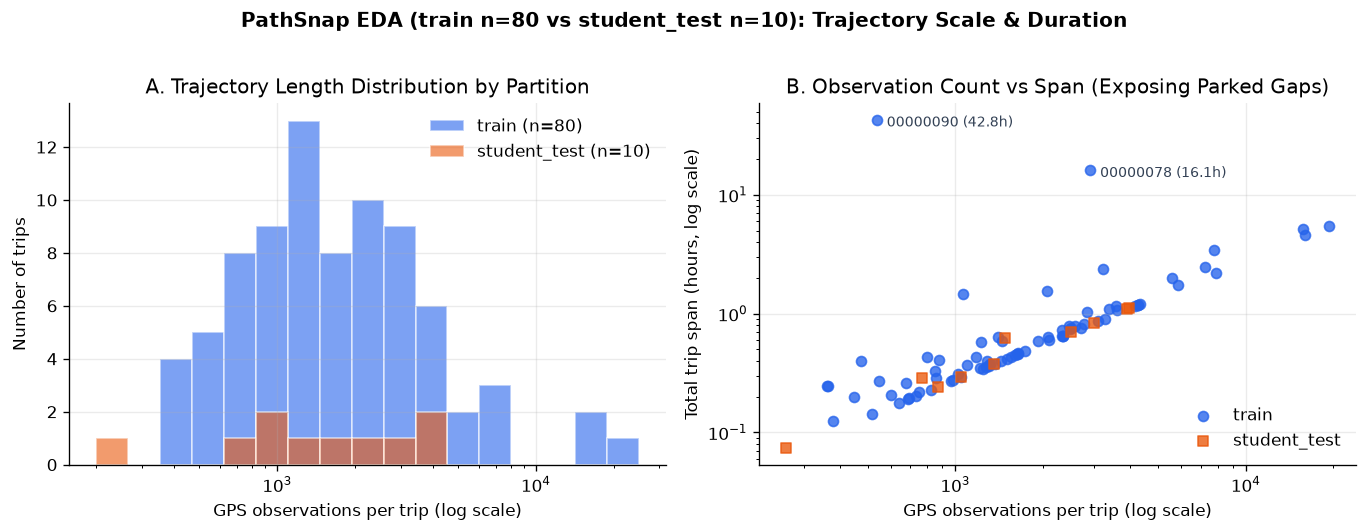

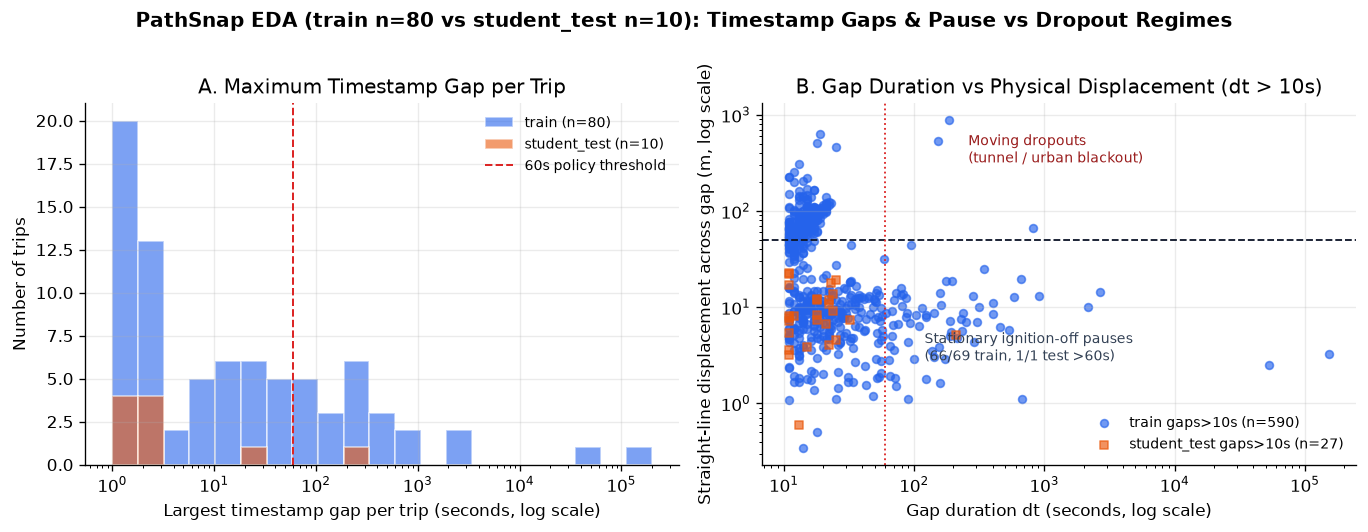

In [7]:
# 01: Trajectory sizes & trip durations by partition
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
bins = np.logspace(np.log10(200), np.log10(25000), 18)
for p, col in [('train', TRAIN_COLOR), ('student_test', TEST_COLOR)]:
    sub = df[df['partition'] == p]
    axes[0].hist(sub['gps_observations'], bins=bins, alpha=0.6, color=col, edgecolor='white', label=f'{p} (n={len(sub)})')
axes[0].set_xscale('log')
axes[0].set_xlabel('GPS observations per trip (log scale)')
axes[0].set_ylabel('Number of trips')
axes[0].set_title('A. Trajectory Length Distribution by Partition')
axes[0].legend(frameon=False)

for p, col, mk in [('train', TRAIN_COLOR, 'o'), ('student_test', TEST_COLOR, 's')]:
    sub = df[df['partition'] == p]
    axes[1].scatter(sub['gps_observations'], sub['duration_s'] / 3600.0, c=col, marker=mk, s=36, alpha=0.78, label=p)
for _, r in df.nlargest(2, 'duration_s').iterrows():
    axes[1].annotate(f"{r['trip_id']} ({r['duration_s']/3600:.1f}h)", (r['gps_observations'], r['duration_s']/3600.0),
                     xytext=(6, -4), textcoords='offset points', fontsize=8.5, color='#334155')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('GPS observations per trip (log scale)')
axes[1].set_ylabel('Total trip span (hours, log scale)')
axes[1].set_title('B. Observation Count vs Span (Exposing Parked Gaps)')
axes[1].legend(frameon=False)

fig.suptitle('PathSnap EDA (train n=80 vs student_test n=10): Trajectory Scale & Duration', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUT / '01_gps_observations_hist.png', bbox_inches='tight')
plt.show()
plt.close(fig)

# 02: Timestamp gap distribution (log10) & displacement vs dt regime classification
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
gap_bins = np.logspace(0, np.log10(200000), 22)
for p, col in [('train', TRAIN_COLOR), ('student_test', TEST_COLOR)]:
    sub = df[df['partition'] == p]
    axes[0].hist(np.clip(sub['timestamp_max_gap_s'], 1.0, None), bins=gap_bins, alpha=0.6, color=col, edgecolor='white', label=f'{p} (n={len(sub)})')
axes[0].axvline(60, color='#dc2626', linestyle='--', linewidth=1.2, label='60s policy threshold')
axes[0].set_xscale('log')
axes[0].set_xlabel('Largest timestamp gap per trip (seconds, log scale)')
axes[0].set_ylabel('Number of trips')
axes[0].set_title('A. Maximum Timestamp Gap per Trip')
axes[0].legend(frameon=False, fontsize=8.5)

for p, col, mk in [('train', TRAIN_COLOR, 'o'), ('student_test', TEST_COLOR, 's')]:
    sub = df_gaps[df_gaps['partition'] == p]
    axes[1].scatter(sub['dt_s'], np.maximum(sub['dist_m'], 0.2), c=col, marker=mk, s=22, alpha=0.65, label=f'{p} gaps>10s (n={len(sub)})')
axes[1].axhline(50.0, color='#0f172a', linestyle='--', linewidth=1.1)
axes[1].axvline(60.0, color='#dc2626', linestyle=':', linewidth=1.1)
axes[1].text(120, 2.8, 'Stationary ignition-off pauses\n(66/69 train, 1/1 test >60s)', fontsize=8.5, color='#334155')
axes[1].text(260, 320.0, 'Moving dropouts\n(tunnel / urban blackout)', fontsize=8.5, color='#991b1b')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Gap duration dt (seconds, log scale)')
axes[1].set_ylabel('Straight-line displacement across gap (m, log scale)')
axes[1].set_title('B. Gap Duration vs Physical Displacement (dt > 10s)')
axes[1].legend(frameon=False, fontsize=8.5, loc='lower right')

fig.suptitle('PathSnap EDA (train n=80 vs student_test n=10): Timestamp Gaps & Pause vs Dropout Regimes', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUT / '02_max_timestamp_gap_hist.png', bbox_inches='tight')
plt.show()
plt.close(fig)

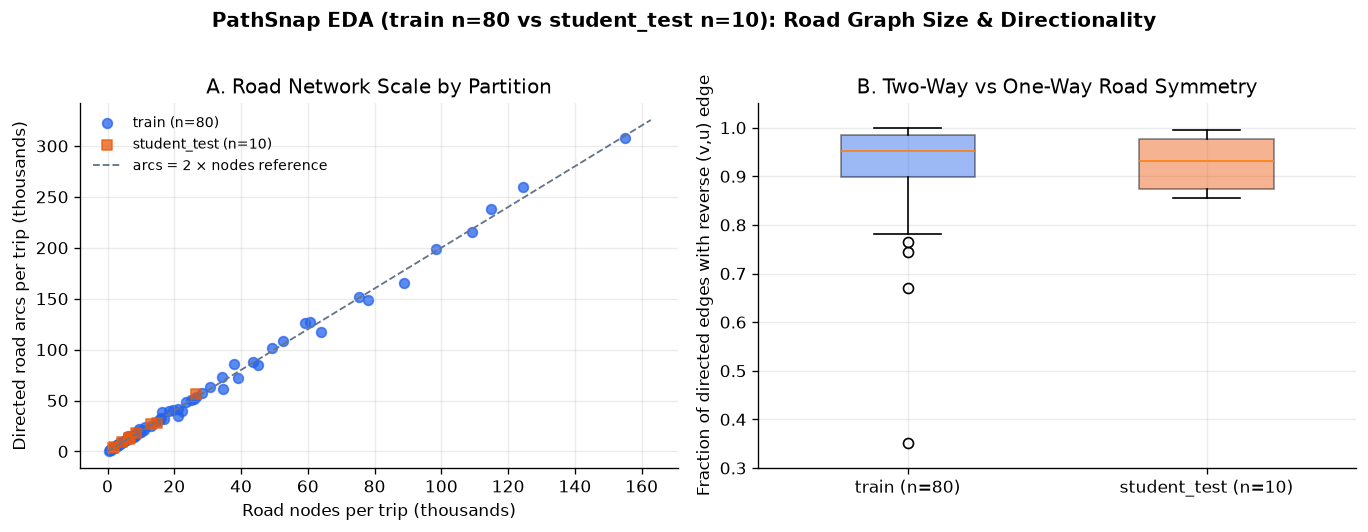

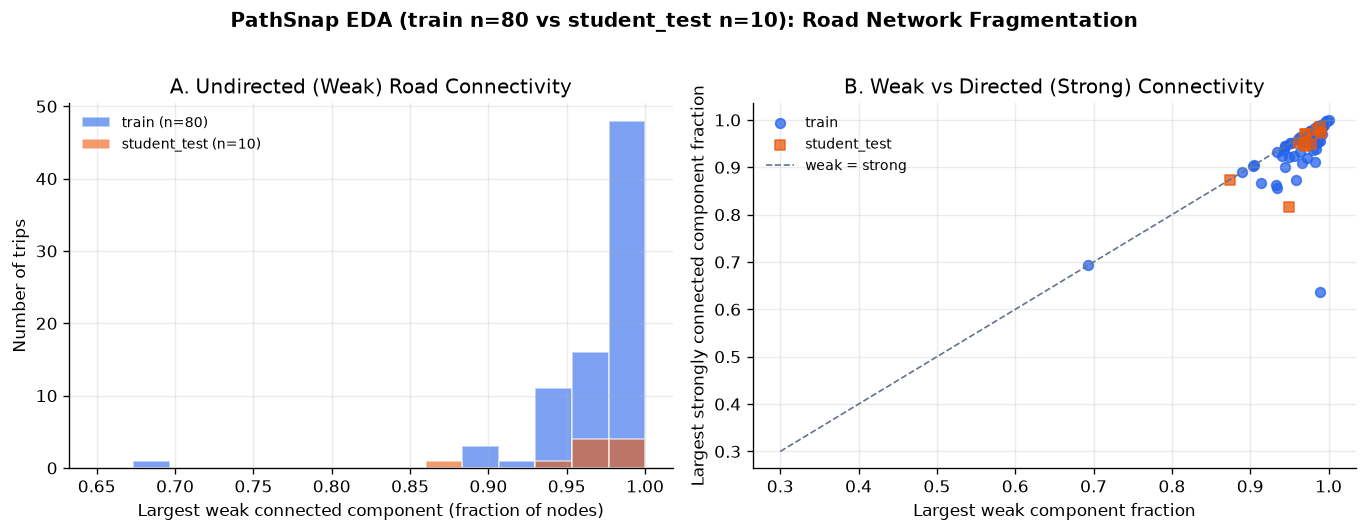

In [8]:
# 03: Road network scale & bidirectional street coverage by partition
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
for p, col, mk in [('train', TRAIN_COLOR, 'o'), ('student_test', TEST_COLOR, 's')]:
    sub = df[df['partition'] == p]
    axes[0].scatter(sub['road_nodes'] / 1000.0, sub['road_arcs'] / 1000.0, c=col, marker=mk, s=34, alpha=0.75, label=f'{p} (n={len(sub)})')
x_line = np.linspace(0, df['road_nodes'].max() / 1000.0 * 1.05, 50)
axes[0].plot(x_line, 2.0 * x_line, '--', color='#64748b', linewidth=1.1, label='arcs = 2 × nodes reference')
axes[0].set_xlabel('Road nodes per trip (thousands)')
axes[0].set_ylabel('Directed road arcs per trip (thousands)')
axes[0].set_title('A. Road Network Scale by Partition')
axes[0].legend(frameon=False, fontsize=8.5)

data_bidir = [
    df.loc[df['partition'] == 'train', 'bidirectional_arc_fraction'].values,
    df.loc[df['partition'] == 'student_test', 'bidirectional_arc_fraction'].values,
]
bp = axes[1].boxplot(data_bidir, tick_labels=['train (n=80)', 'student_test (n=10)'], patch_artist=True, widths=0.45)
for patch, col in zip(bp['boxes'], [TRAIN_COLOR, TEST_COLOR]):
    patch.set_facecolor(col)
    patch.set_alpha(0.45)
axes[1].set_ylabel('Fraction of directed edges with reverse (v,u) edge')
axes[1].set_title('B. Two-Way vs One-Way Road Symmetry')
axes[1].set_ylim(0.3, 1.05)

fig.suptitle('PathSnap EDA (train n=80 vs student_test n=10): Road Graph Size & Directionality', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUT / '03_road_network_size.png', bbox_inches='tight')
plt.show()
plt.close(fig)

# 04: Weak vs Strong Connectivity by partition
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
for p, col in [('train', TRAIN_COLOR), ('student_test', TEST_COLOR)]:
    sub = df[df['partition'] == p]
    axes[0].hist(sub['largest_component_fraction'], bins=np.linspace(0.65, 1.0, 16), alpha=0.6, color=col, edgecolor='white', label=f'{p} (n={len(sub)})')
axes[0].set_xlabel('Largest weak connected component (fraction of nodes)')
axes[0].set_ylabel('Number of trips')
axes[0].set_title('A. Undirected (Weak) Road Connectivity')
axes[0].legend(frameon=False, fontsize=8.5)

for p, col, mk in [('train', TRAIN_COLOR, 'o'), ('student_test', TEST_COLOR, 's')]:
    sub = df[df['partition'] == p]
    axes[1].scatter(sub['largest_component_fraction'], sub['largest_strong_component_fraction'], c=col, marker=mk, s=34, alpha=0.75, label=p)
axes[1].plot([0.3, 1.0], [0.3, 1.0], '--', color='#64748b', linewidth=1.0, label='weak = strong')
axes[1].set_xlabel('Largest weak component fraction')
axes[1].set_ylabel('Largest strongly connected component fraction')
axes[1].set_title('B. Weak vs Directed (Strong) Connectivity')
axes[1].legend(frameon=False, fontsize=8.5)

fig.suptitle('PathSnap EDA (train n=80 vs student_test n=10): Road Network Fragmentation', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUT / '04_connectivity.png', bbox_inches='tight')
plt.show()
plt.close(fig)

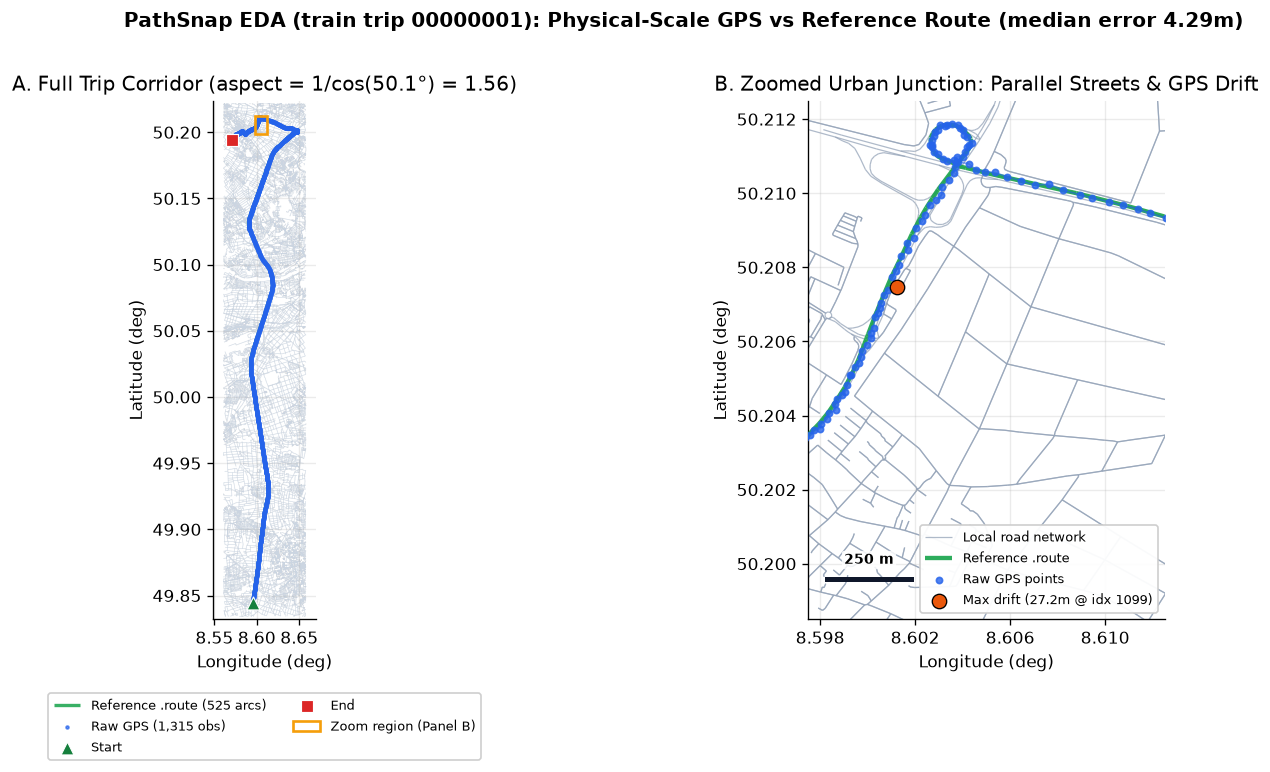

In [9]:
# 05: Aspect-corrected full corridor & zoomed urban multipath view on train/00000001
with ZipFile(DATA_ZIP) as zf:
    gps1 = load_file(zf, 'train', '00000001', 'track')
    nodes1 = load_file(zf, 'train', '00000001', 'nodes')
    arcs1 = load_file(zf, 'train', '00000001', 'arcs', np.int64)
    route1 = load_file(zf, 'train', '00000001', 'route', np.int64)

lat0_1 = float(np.median(gps1[:, 1]))
lon0_1 = float(np.median(gps1[:, 0]))
aspect_deg = 1.0 / math.cos(math.radians(lat0_1))

# Compute exact GPS-to-route distances for trip 00000001
gx1, gy1 = to_local_xy(gps1[:, 0], gps1[:, 1], lon0_1, lat0_1)
nx1, ny1 = to_local_xy(nodes1[:, 0], nodes1[:, 1], lon0_1, lat0_1)
r1_arcs = arcs1[route1]
gps1_dists = point_to_segments_min_dist_m(
    np.column_stack([gx1, gy1]),
    np.column_stack([nx1[r1_arcs[:, 0]], ny1[r1_arcs[:, 0]]]),
    np.column_stack([nx1[r1_arcs[:, 1]], ny1[r1_arcs[:, 1]]]),
)
max_drift_idx = int(np.argmax(gps1_dists))

# Select road arcs within full trip bounding box
pad_lon, pad_lat = 0.012, 0.010
in_full = (
    (nodes1[:, 0] >= gps1[:, 0].min() - pad_lon) & (nodes1[:, 0] <= gps1[:, 0].max() + pad_lon) &
    (nodes1[:, 1] >= gps1[:, 1].min() - pad_lat) & (nodes1[:, 1] <= gps1[:, 1].max() + pad_lat)
)
bg_arcs = arcs1[in_full[arcs1[:, 0]] & in_full[arcs1[:, 1]]]
bg_lines = np.stack([nodes1[bg_arcs[:, 0]], nodes1[bg_arcs[:, 1]]], axis=1)
ref_lines = np.stack([nodes1[r1_arcs[:, 0]], nodes1[r1_arcs[:, 1]]], axis=1)

# Zoom box centered around urban junction & max drift point (idx 1099)
zx0, zx1 = 8.5975, 8.6125
zy0, zy1 = 50.1985, 50.2125
in_zoom = (
    (nodes1[:, 0] >= zx0 - 0.002) & (nodes1[:, 0] <= zx1 + 0.002) &
    (nodes1[:, 1] >= zy0 - 0.002) & (nodes1[:, 1] <= zy1 + 0.002)
)
z_arcs = arcs1[in_zoom[arcs1[:, 0]] & in_zoom[arcs1[:, 1]]]
z_lines = np.stack([nodes1[z_arcs[:, 0]], nodes1[z_arcs[:, 1]]], axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12.2, 6.4), gridspec_kw={'width_ratios': [1.0, 1.4]})

# Left panel: full 41 km corridor
axes[0].add_collection(LineCollection(bg_lines, colors='#cbd5e1', linewidths=0.35, alpha=0.55, zorder=1))
axes[0].add_collection(LineCollection(ref_lines, colors=ROUTE_COLOR, linewidths=2.0, alpha=0.85, zorder=3, label='Reference .route (525 arcs)'))
axes[0].scatter(gps1[:, 0], gps1[:, 1], s=3, c=TRAIN_COLOR, alpha=0.7, zorder=4, label='Raw GPS (1,315 obs)')
axes[0].scatter([gps1[0, 0]], [gps1[0, 1]], s=60, c='#15803d', marker='^', edgecolor='white', linewidth=0.7, zorder=6, label='Start')
axes[0].scatter([gps1[-1, 0]], [gps1[-1, 1]], s=60, c='#dc2626', marker='s', edgecolor='white', linewidth=0.7, zorder=6, label='End')
axes[0].add_patch(Rectangle((zx0, zy0), zx1 - zx0, zy1 - zy0, fill=False, edgecolor='#f59e0b', linewidth=1.6, zorder=7, label='Zoom region (Panel B)'))
axes[0].set_xlim(gps1[:, 0].min() - 0.022, gps1[:, 0].max() + 0.022)
axes[0].set_ylim(gps1[:, 1].min() - 0.012, gps1[:, 1].max() + 0.012)
axes[0].set_aspect(aspect_deg)
axes[0].set_xlabel('Longitude (deg)')
axes[0].set_ylabel('Latitude (deg)')
axes[0].set_title(f'A. Full Trip Corridor (aspect = 1/cos({lat0_1:.1f}°) = {aspect_deg:.2f})')
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=8.0, frameon=True, facecolor='white', framealpha=0.95)

# Right panel: zoomed urban parallel-street multipath
axes[1].add_collection(LineCollection(z_lines, colors='#94a3b8', linewidths=0.75, alpha=0.75, zorder=1, label='Local road network'))
axes[1].add_collection(LineCollection(ref_lines, colors=ROUTE_COLOR, linewidths=2.6, alpha=0.9, zorder=3, label='Reference .route'))
axes[1].plot(gps1[:, 0], gps1[:, 1], color=TRAIN_COLOR, linewidth=1.0, alpha=0.55, zorder=4)
axes[1].scatter(gps1[:, 0], gps1[:, 1], s=14, c=TRAIN_COLOR, alpha=0.8, zorder=5, label='Raw GPS points')
axes[1].scatter([gps1[max_drift_idx, 0]], [gps1[max_drift_idx, 1]], s=75, c='#ea580c', edgecolor='black', linewidth=0.8, zorder=7,
                label=f'Max drift ({gps1_dists[max_drift_idx]:.1f}m @ idx {max_drift_idx})')
# 250 m physical scale bar placed cleanly in bottom-left open margin
bar_deg = 250.0 / (EARTH_RADIUS_M * math.radians(1.0) * math.cos(math.radians(50.2)))
axes[1].plot([zx0 + 0.0008, zx0 + 0.0008 + bar_deg], [zy0 + 0.0011, zy0 + 0.0011], color='#0f172a', linewidth=3.0, zorder=8)
axes[1].text(zx0 + 0.0008 + bar_deg / 2.0, zy0 + 0.0015, '250 m', ha='center', fontsize=8.5, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.85))
axes[1].set_xlim(zx0, zx1)
axes[1].set_ylim(zy0, zy1)
axes[1].set_xticks([8.598, 8.602, 8.606, 8.610])
axes[1].set_aspect(aspect_deg)
axes[1].set_xlabel('Longitude (deg)')
axes[1].set_ylabel('Latitude (deg)')
axes[1].set_title('B. Zoomed Urban Junction: Parallel Streets & GPS Drift')
axes[1].legend(loc='lower right', fontsize=8, frameon=True, facecolor='white', framealpha=0.95)

fig.suptitle(f'PathSnap EDA (train trip 00000001): Physical-Scale GPS vs Reference Route (median error {np.median(gps1_dists):.2f}m)', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUT / '05_reference_vs_gps.png', bbox_inches='tight')
plt.show()
plt.close(fig)

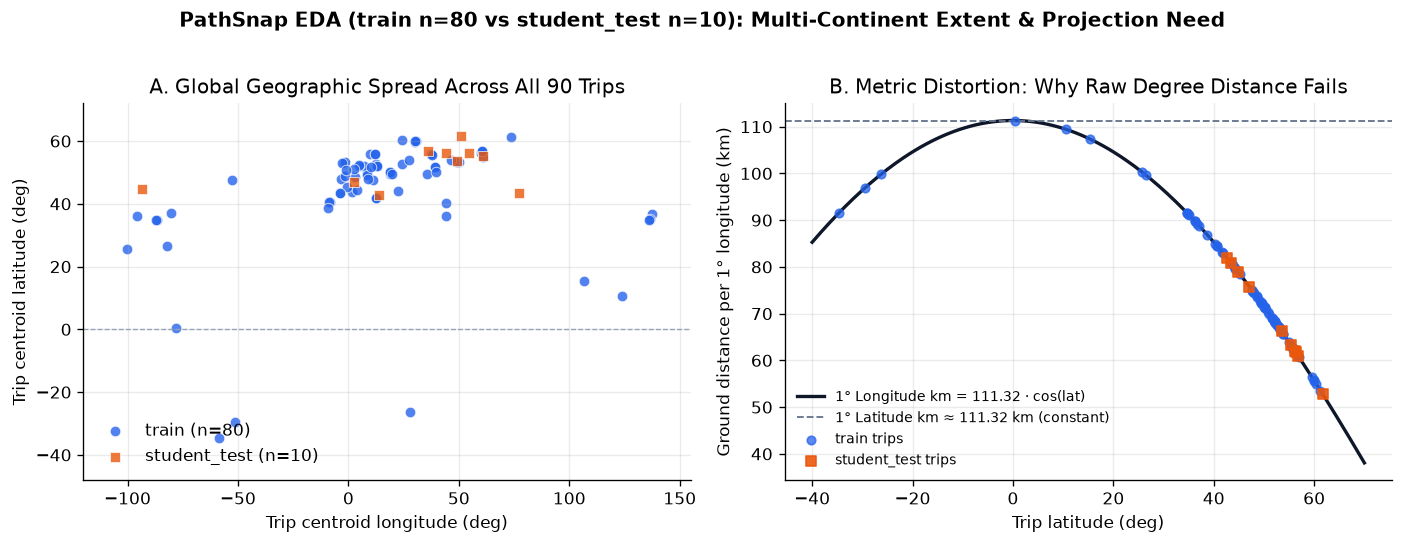

In [10]:
# 07: Global trip centroids & cos(lat) longitudinal distortion curve
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.4))
for p, col, mk in [('train', TRAIN_COLOR, 'o'), ('student_test', TEST_COLOR, 's')]:
    sub = df[df['partition'] == p]
    axes[0].scatter(sub['centroid_lon'], sub['centroid_lat'], c=col, marker=mk, s=40, alpha=0.8, edgecolor='white', linewidth=0.5, label=f'{p} (n={len(sub)})')
axes[0].axhline(0, color='#94a3b8', linewidth=0.8, linestyle='--')
axes[0].set_xlim(-120, 155)
axes[0].set_ylim(-48, 72)
axes[0].set_xlabel('Trip centroid longitude (deg)')
axes[0].set_ylabel('Trip centroid latitude (deg)')
axes[0].set_title('A. Global Geographic Spread Across All 90 Trips')
axes[0].legend(frameon=False, loc='lower left')

lats = np.linspace(-40, 70, 200)
axes[1].plot(lats, np.cos(np.radians(lats)) * 111.32, color='#0f172a', linewidth=2.0, label='1° Longitude km = 111.32 · cos(lat)')
axes[1].axhline(111.32, color='#64748b', linestyle='--', linewidth=1.1, label='1° Latitude km ≈ 111.32 km (constant)')
axes[1].scatter(df[df['partition'] == 'train']['centroid_lat'], df[df['partition'] == 'train']['lon_scale_cos_lat'] * 111.32,
                c=TRAIN_COLOR, s=26, alpha=0.75, zorder=4, label='train trips')
axes[1].scatter(df[df['partition'] == 'student_test']['centroid_lat'], df[df['partition'] == 'student_test']['lon_scale_cos_lat'] * 111.32,
                c=TEST_COLOR, marker='s', s=34, alpha=0.9, zorder=5, label='student_test trips')
axes[1].set_xlabel('Trip latitude (deg)')
axes[1].set_ylabel('Ground distance per 1° longitude (km)')
axes[1].set_title('B. Metric Distortion: Why Raw Degree Distance Fails')
axes[1].legend(frameon=False, fontsize=8.2)

fig.suptitle('PathSnap EDA (train n=80 vs student_test n=10): Multi-Continent Extent & Projection Need', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUT / '07_global_geography_and_projection.png', bbox_inches='tight')
plt.show()
plt.close(fig)

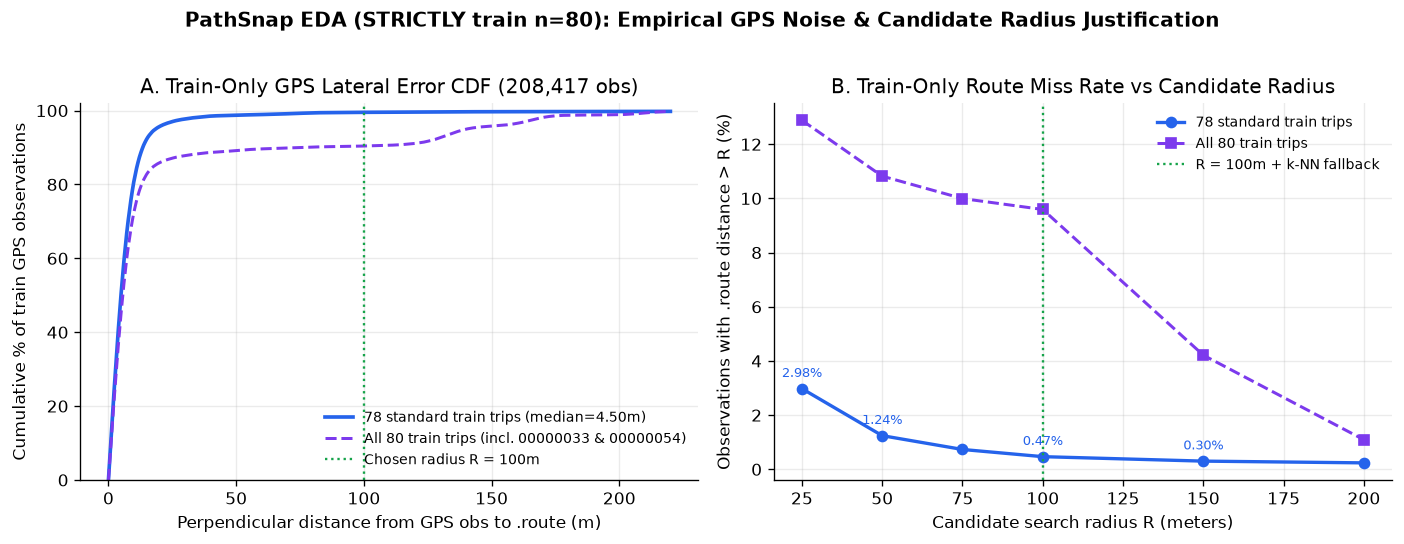

In [11]:
# 08: Train-only GPS-to-route error CDF, candidate search radius sweep, & jitter inflation
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.4))

x_grid = np.linspace(0, 220, 400)
cdf_std = [np.mean(std_d <= xv) * 100.0 for xv in x_grid]
cdf_all = [np.mean(all_d <= xv) * 100.0 for xv in x_grid]
axes[0].plot(x_grid, cdf_std, color=TRAIN_COLOR, linewidth=2.2, label='78 standard train trips (median=4.50m)')
axes[0].plot(x_grid, cdf_all, color='#7c3aed', linestyle='--', linewidth=1.8, label='All 80 train trips (incl. 00000033 & 00000054)')
axes[0].axvline(100, color='#16a34a', linestyle=':', linewidth=1.4, label='Chosen radius R = 100m')
axes[0].set_xlabel('Perpendicular distance from GPS obs to .route (m)')
axes[0].set_ylabel('Cumulative % of train GPS observations')
axes[0].set_title('A. Train-Only GPS Lateral Error CDF (208,417 obs)')
axes[0].set_ylim(0, 102)
axes[0].legend(frameon=False, fontsize=8.3, loc='lower right')

axes[1].plot(df_sweep['radius_m'], df_sweep['std_78_train_miss_pct'], 'o-', color=TRAIN_COLOR, linewidth=2.0, label='78 standard train trips')
axes[1].plot(df_sweep['radius_m'], df_sweep['all_80_train_miss_pct'], 's--', color='#7c3aed', linewidth=1.8, label='All 80 train trips')
for _, r in df_sweep.iterrows():
    if r['radius_m'] in (25, 50, 100, 150):
        axes[1].annotate(f"{r['std_78_train_miss_pct']:.2f}%", (r['radius_m'], r['std_78_train_miss_pct']),
                         xytext=(0, 7), textcoords='offset points', ha='center', fontsize=8, color=TRAIN_COLOR)
axes[1].axvline(100, color='#16a34a', linestyle=':', linewidth=1.4, label='R = 100m + k-NN fallback')
axes[1].set_xlabel('Candidate search radius R (meters)')
axes[1].set_ylabel('Observations with .route distance > R (%)')
axes[1].set_title('B. Train-Only Route Miss Rate vs Candidate Radius')
axes[1].legend(frameon=False, fontsize=8.3)

fig.suptitle('PathSnap EDA (STRICTLY train n=80): Empirical GPS Noise & Candidate Radius Justification', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUT / '08_train_gps_noise_and_candidate_radius.png', bbox_inches='tight')
plt.show()
plt.close(fig)

## 6. Interactive Folium Map (`train` Trip `00000001`)

Improvements over the earlier map:
- Covers the **entire 41 km corridor** of `train/00000001` (`<= 120 m` of any GPS point), rather than only the first 75 observations.
- Uses **multi-polylines** and `prefer_canvas=True` for smooth browser rendering and compact file size.
- Organises every layer into toggleable `FeatureGroup`s (`Corridor road network`, `Reference route`, `Raw GPS line`, `Sampled & outlier GPS points`, `Key landmarks`) with dual basemaps (`CartoDB Positron` + `OpenStreetMap`) and an open `LayerControl`.
- Includes Start/End/Max-Drift/16s-Gap markers, rich hover tooltips (`idx`, `t_s`, `speed_kmh`, `dist_to_route_m`), and a fixed **HTML Legend & Summary Card** (Deliverables.pdf Section 6).

In [12]:
# Spatial-grid corridor filter across ALL 1,315 GPS observations of train/00000001
cell_m = 150.0
corridor_radius_m = 120.0
pt_grid = defaultdict(list)
for px, py in zip(gx1, gy1):
    cgx, cgy = int(math.floor(px / cell_m)), int(math.floor(py / cell_m))
    pt_grid[(cgx, cgy)].append((float(px), float(py)))

corridor_segs = []
for u, v in arcs1:
    ax, ay = float(nx1[u]), float(ny1[u])
    bx, by = float(nx1[v]), float(ny1[v])
    gx_min = int(math.floor(min(ax, bx) / cell_m)) - 1
    gx_max = int(math.floor(max(ax, bx) / cell_m)) + 1
    gy_min = int(math.floor(min(ay, by) / cell_m)) - 1
    gy_max = int(math.floor(max(ay, by) / cell_m)) + 1
    nearby_pts = []
    for cx in range(gx_min, gx_max + 1):
        for cy in range(gy_min, gy_max + 1):
            if (cx, cy) in pt_grid:
                nearby_pts.extend(pt_grid[(cx, cy)])
    if not nearby_pts:
        continue
    dx, dy = bx - ax, by - ay
    l2 = dx * dx + dy * dy
    keep = False
    for px, py in nearby_pts:
        if l2 == 0.0:
            d = math.hypot(px - ax, py - ay)
        else:
            proj = max(0.0, min(1.0, ((px - ax) * dx + (py - ay) * dy) / l2))
            d = math.hypot(px - (ax + proj * dx), py - (ay + proj * dy))
        if d <= corridor_radius_m:
            keep = True
            break
    if keep:
        corridor_segs.append([[float(nodes1[u, 1]), float(nodes1[u, 0])], [float(nodes1[v, 1]), float(nodes1[v, 0])]])

print(f'Full-corridor road arcs within {corridor_radius_m:.0f}m of trip 00000001: {len(corridor_segs):,} / {len(arcs1):,}')

# Smoothed per-point speed for informative GPS hover tooltips
dt1 = np.round(np.diff(gps1[:, 2]), 6)
step_d1 = haversine_m(gps1[:-1, 1], gps1[:-1, 0], gps1[1:, 1], gps1[1:, 0])
spd1 = np.zeros(len(gps1))
spd1[1:] = np.where(dt1 > 0, step_d1 / dt1 * 3.6, 0.0)

m = folium.Map(
    location=[lat0_1, lon0_1],
    zoom_start=11,
    tiles=None,
    prefer_canvas=True,
    control_scale=True,
)
folium.TileLayer(
    tiles='https://{s}.basemaps.cartocdn.com/light_all/{z}/{x}/{y}{r}.png',
    attr='&copy; OpenStreetMap contributors &copy; CARTO',
    name='CartoDB Positron (clean)',
    show=True,
).add_to(m)
folium.TileLayer('OpenStreetMap', name='OpenStreetMap (streets)', show=False).add_to(m)

# 1. Corridor road network (toggleable, single multi-polyline for speed & compact HTML)
fg_net = folium.FeatureGroup(name='Corridor road network (<=120m)', show=True)
folium.PolyLine(corridor_segs, color='#64748b', weight=1.1, opacity=0.45).add_to(fg_net)
fg_net.add_to(m)

# 2. Reference route segments (segment-by-segment multi-polyline, no false bridging)
ref_segs = [
    [[float(nodes1[u, 1]), float(nodes1[u, 0])], [float(nodes1[v, 1]), float(nodes1[v, 0])]]
    for u, v in r1_arcs
]
fg_ref = folium.FeatureGroup(name='Reference route (.route, 525 arcs)', show=True)
folium.PolyLine(ref_segs, color=ROUTE_COLOR, weight=4.0, opacity=0.85, tooltip='Reference route (.route)').add_to(fg_ref)
fg_ref.add_to(m)

# 3. Raw GPS trajectory line
fg_gps_line = folium.FeatureGroup(name='Raw GPS trajectory (chronological)', show=True)
folium.PolyLine(
    gps1[:, [1, 0]].tolist(),
    color=TRAIN_COLOR,
    weight=2.0,
    opacity=0.65,
    tooltip='Raw GPS order (not snapped)',
).add_to(fg_gps_line)
fg_gps_line.add_to(m)

# 4. Sampled GPS dots + all high-drift points (>15m)
fg_pts = folium.FeatureGroup(name='GPS points (blue) & drift >15m (orange)', show=True)
sample_idx = set(range(0, len(gps1), 6)) | set(np.where(gps1_dists > 15.0)[0].tolist())
for i in sorted(sample_idx):
    is_hi = gps1_dists[i] > 15.0
    folium.CircleMarker(
        location=[float(gps1[i, 1]), float(gps1[i, 0])],
        radius=4.5 if is_hi else 2.2,
        color='#c2410c' if is_hi else TRAIN_COLOR,
        fill=True,
        fill_color='#fb923c' if is_hi else TRAIN_COLOR,
        fill_opacity=0.9 if is_hi else 0.75,
        weight=1.0 if is_hi else 0.5,
        tooltip=f'GPS #{i} | t={gps1[i,2]:.0f}s | speed={spd1[i]:.1f} km/h | route_err={gps1_dists[i]:.1f} m',
    ).add_to(fg_pts)
fg_pts.add_to(m)

# 5. Landmarks: Start, End, Max drift (idx 1099), 16s gap (idx 1220)
fg_marks = folium.FeatureGroup(name='Key landmarks (Start / End / Max drift / 16s gap)', show=True)
folium.Marker(
    [float(gps1[0, 1]), float(gps1[0, 0])],
    popup=f'<b>Trip Start</b><br>t = {gps1[0,2]:.0f}s<br>lat={gps1[0,1]:.5f}, lon={gps1[0,0]:.5f}',
    tooltip='Trip Start (idx 0, t=1s)',
    icon=folium.Icon(color='green', icon='play', prefix='fa'),
).add_to(fg_marks)
folium.Marker(
    [float(gps1[-1, 1]), float(gps1[-1, 0])],
    popup=f'<b>Trip End</b><br>t = {gps1[-1,2]:.0f}s<br>lat={gps1[-1,1]:.5f}, lon={gps1[-1,0]:.5f}',
    tooltip=f'Trip End (idx {len(gps1)-1}, t={gps1[-1,2]:.0f}s)',
    icon=folium.Icon(color='red', icon='stop', prefix='fa'),
).add_to(fg_marks)
folium.Marker(
    [float(gps1[max_drift_idx, 1]), float(gps1[max_drift_idx, 0])],
    popup=f'<b>Max Lateral Drift</b><br>idx={max_drift_idx}, t={gps1[max_drift_idx,2]:.0f}s<br>dist_to_route={gps1_dists[max_drift_idx]:.2f} m',
    tooltip=f'Max drift: {gps1_dists[max_drift_idx]:.1f}m (idx {max_drift_idx})',
    icon=folium.Icon(color='orange', icon='exclamation-triangle', prefix='fa'),
).add_to(fg_marks)
gap16_idx = int(np.argmax(dt1))
folium.Marker(
    [float(gps1[gap16_idx, 1]), float(gps1[gap16_idx, 0])],
    popup=f'<b>Max Timestamp Gap (dt={dt1[gap16_idx]:.0f}s)</b><br>idx={gap16_idx}->{gap16_idx+1}<br>dist={step_d1[gap16_idx]:.1f} m',
    tooltip=f'Max gap {dt1[gap16_idx]:.0f}s ({step_d1[gap16_idx]:.1f}m)',
    icon=folium.Icon(color='blue', icon='clock', prefix='fa'),
).add_to(fg_marks)
fg_marks.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m.fit_bounds([[float(gps1[:, 1].min()), float(gps1[:, 0].min())], [float(gps1[:, 1].max()), float(gps1[:, 0].max())]])

# Floating Legend & Trip Summary Card
legend_html = f"""
<div style="
    position: fixed; bottom: 44px; left: 14px; z-index: 9999;
    background: rgba(255, 255, 255, 0.94); padding: 11px 14px;
    border-radius: 8px; border: 1px solid #cbd5e1;
    box-shadow: 0 2px 8px rgba(15, 23, 42, 0.14);
    font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', sans-serif;
    font-size: 12px; color: #0f172a; line-height: 1.45; max-width: 280px;">
  <div style="font-weight: 700; font-size: 13px; margin-bottom: 4px;">
    PathSnap Case Study &mdash; <code>train / 00000001</code>
  </div>
  <div style="color: #475569; font-size: 11px; margin-bottom: 7px;">
    1,315 GPS obs &bull; 525 route arcs &bull; 49.9 km &bull; median err {np.median(gps1_dists):.2f} m
  </div>
  <div><span style="display:inline-block;width:14px;height:3px;background:{ROUTE_COLOR};vertical-align:middle;margin-right:6px;"></span>Reference route (<code>.route</code>)</div>
  <div><span style="display:inline-block;width:14px;height:3px;background:{TRAIN_COLOR};vertical-align:middle;margin-right:6px;"></span>Raw GPS trajectory (chronological)</div>
  <div><span style="display:inline-block;width:9px;height:9px;border-radius:50%;background:#fb923c;border:1px solid #c2410c;vertical-align:middle;margin-right:6px;margin-left:2px;"></span>High lateral drift (&gt;15 m; max {gps1_dists[max_drift_idx]:.1f} m)</div>
  <div><span style="display:inline-block;width:14px;height:2px;background:#64748b;vertical-align:middle;margin-right:6px;"></span>Corridor road network (&le;120 m, {len(corridor_segs):,} arcs)</div>
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))

map_path = OUT / '06_train_trip_00000001_map.html'
m.save(str(map_path))
print(f'Saved interactive Folium map: {map_path} ({map_path.stat().st_size / 1024:.1f} KB)')

Full-corridor road arcs within 120m of trip 00000001: 8,728 / 165,790
Saved interactive Folium map: PathSnap_EDA_outputs/06_train_trip_00000001_map.html (659.6 KB)


## 7. Report Section 2.2 Synthesis — Preprocessing, Feature Choices & Modelling Handoff

### Q1. How did you preprocess the data? (Implemented in EDA vs Planned for Modelling)

**Implemented & validated in this EDA:**
- **Schema & type validation:** Parsed headerless `.track`, `.nodes`, `.arcs`, and `.route` files with explicit rank guarantees and confirmed 0 missing cells, 0 invalid coordinate bounds, and 0 out-of-range node/arc indices across all `80 train` and `10 student_test` trips.
- **Float-safe timestamp auditing:** Rounded `np.diff(t)` to 6 decimals to eliminate IEEE-754 comparison bugs on fractional timestamps (`train/00000002`, `00000071`, `00000097`), confirming `96.50%` (`train`) and `98.62%` (`student_test`) 1.0 s sampling (`96.68%` overall).
- **Per-trip local metric projection:** Built `to_local_xy(lon, lat, lon0, lat0)` centered at each trip's median `(lon, lat)` because trips span `-100.42°` to `+137.24°` lon and `-34.64°` to `+61.70°` lat (where `1°` longitude shrinks to `52.8 km`), invalidating raw degree Euclidean distance and any single global UTM zone.
- **Graph & route edge-case indexing:** Preserved parallel `(u, v)` edges strictly by `arc_id` (`53/80` train and `7/10` student_test graphs have duplicate `(u, v)` pairs, and `.route` actually traverses them `11` times), flagged `24` self-loops and `82` distinct-node zero-length arcs, and tagged `14` directed `.route` breaks (`13` in `10` train trips, `1` in `student_test/00000076`).

**Planned for the downstream candidate-generation & ML pipeline (fit strictly on `train`):**
1. **Gap-regime segmentation:** Split or zero-weight HMM transitions at moving dropouts (`dt > 10s` with displacement `>= 50m`, or `dt > 60s`), while keeping parked pauses (`dist < 50m`) anchored rather than falsely smoothing across multi-hour stops (`00000090` = 42.5 h, `00000078` = 14.7 h).
2. **Candidate generation (`R = 100 m` + k-NN fallback):** For each GPS point, retrieve all arcs within `100 m` in local meters (covering `99.53%` of standard-trip observations—only `0.47%` miss rate—based on the `train`-only noise sweep), falling back to `k = 5` nearest arcs when a point has `0` candidates within `100 m`.
3. **Training-set alignment & outlier handling:** Derive per-GPS supervised candidate labels only on `train` via Viterbi/sequence alignment against `.route`, explicitly flagging off-route segments (`train/00000033`, `train/00000054`) so unmapped tracks do not corrupt emission calibration.
4. **Leakage-free scaling:** Fit all feature scalers, class weights, and hyperparameters on `train` cross-validation folds only (`GroupKFold` by `trip_id`).

---

### Q2. What patterns did we observe, and what candidate features should be extracted and why?

**Key empirical patterns observed:**
- **GPS jitter vs true motion:** Median lateral error on standard `train` trips is `4.50 m` (`p95 ≈ 25 m`), but 1 Hz jitter inflates raw cumulative step length up to `3–5×` (`00000021`: `128.8 km` 1 s sum vs `51.1 km` 10 s-smoothed vs `48.6 km` `.route`). Point-to-point raw bearing is therefore noisy at low speeds (`< 5 km/h`).
- **One-way asymmetry & disconnected islands:** Bidirectional arc fraction drops as low as `35.1%` in `train`, largest weak component drops to `0.693`, and strong connectivity is lower still — transitions must respect directed topology (`arcs` as hidden states).
- **Run-length compressed routes:** `.route` averages `~5.6` GPS points per arc with `0` consecutive duplicate `arc_id`s, meaning consecutive GPS observations frequently stay on the **same `arc_id`** (self-transition) or advance across `v -> u'` connections.

**Extracted candidate `(GPS obs i, candidate arc a)` features and rationale:**
1. **Spatial emission geometry:** Perpendicular distance `d_perp(i, a)` (meters), endpoint-clipped projection parameter `alpha in [0, 1]`, and relative distance margin `d_perp(i, a) - min_c d_perp(i, c)` (separates the true road from parallel side-streets and intersection corners).
2. **Smoothed kinematic alignment:** `cos(Δθ)` and `|sin(Δθ)|` between a multi-second smoothed GPS heading (`t ± 3 s`, masked/neutralized when speed `< 5 km/h` or across gaps) and the directed arc bearing (`u -> v`, guarded against zero-length arcs), plus observed vs expected speed consistency. This resolves parallel opposite-direction lanes and overpasses.
3. **Candidate context & topology:** Arc physical length (m), candidate rank within radius `R`, number of candidates within `30 m` / `100 m` (junction ambiguity indicator), and `in_deg(u) / out_deg(v)` (identifies dead-ends vs through-arterials).
4. **Sequential transition compatibility (for HMM/Viterbi):** Directed shortest-path road distance `d_route(a_{t-1} -> a_t)` vs straight-line GPS step distance `|d_route - d_gps|` (`Viterbi` routing penalty), direct `same-arc` / `v == u'` hop indicator, and `dt`-aware transition relaxation across gaps.